# Mahalanobis distance

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import mahalanobis
from ipywidgets import interact, FloatSlider

The Mahalanobis distance of a point $x$ to the center $\mu$ of a distribution with covariance matrix $\Sigma$ is
$$D_M(x) = \sqrt{(x-\mu)^T\Sigma^{-1}(x-\mu)}.$$
It measures the distance in standard deviations, taking into account the correlation between the variables.

In [2]:
rng = np.random.default_rng(111)

mu = np.array([0, 0])
Sigma = np.array([[2, 0.7], [0.7, 2]])
points = rng.multivariate_normal(mu, Sigma, 200)

In [3]:
# Mahalanobis distance
D_M = np.sqrt(np.diag((points-mu) @ np.linalg.inv(Sigma) @ (points-mu).T))

# Euclidean distance
D_E = np.sqrt(np.sum((points-mu)**2, axis=1))

The same computation with `scipy`, for the first point

In [4]:
print(D_M[0], mahalanobis(points[0], mu, np.linalg.inv(Sigma)))

0.8932320078189117 0.8932320078189117


## Euclidean distance vs Mahalanobis distance

Points at the same Euclidean distance from the center are on a circle. Points at the same Mahalanobis distance are on an ellipse with the shape of the distribution.

In [5]:
def distance_grid(Sigma, limit=5.5, n_grid=200):
    # Both distances to the origin, evaluated on a grid
    g = np.linspace(-limit, limit, n_grid)
    G_1, G_2 = np.meshgrid(g, g)
    P = np.linalg.inv(Sigma)
    grid_M = np.sqrt(P[0, 0]*G_1**2 + 2*P[0, 1]*G_1*G_2 + P[1, 1]*G_2**2)
    grid_E = np.sqrt(G_1**2 + G_2**2)
    return G_1, G_2, grid_E, grid_M

def plot_distances(points, Sigma):
    D_M = np.sqrt(np.sum(((points-mu) @ np.linalg.inv(Sigma)) * (points-mu), axis=1))
    D_E = np.sqrt(np.sum((points-mu)**2, axis=1))
    G_1, G_2, grid_E, grid_M = distance_grid(Sigma)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6.8))
    panels = [(axes[0], D_E, grid_E, 'Euclidean distance', [1.5, 3, 4.5]),
              (axes[1], D_M, grid_M, 'Mahalanobis distance', [1, 2, 3])]
    for ax, D, grid, name, levels in panels:
        CS = ax.contour(G_1, G_2, grid, levels=levels, colors='#555555', linewidths=1, linestyles='--')
        ax.clabel(CS, fmt='%g', fontsize=9)
        sc = ax.scatter(points[:, 0], points[:, 1], c=D, cmap='Blues', vmin=0, s=38,
                        edgecolor='#1f4e79', linewidth=0.5)
        # The farthest point according to each distance
        far = np.argmax(D)
        ax.plot(points[far, 0], points[far, 1], 'o', markersize=14, markerfacecolor='none',
                markeredgecolor='#c1121f', markeredgewidth=2)
        ax.annotate('farthest point', points[far], xytext=(10, 10), textcoords='offset points',
                    color='#c1121f', fontsize=10)
        fig.colorbar(sc, ax=ax, label=name, shrink=0.85)
        ax.set_aspect('equal')
        ax.set_xlim(-5.5, 5.5)
        ax.set_ylim(-5.5, 5.5)
        ax.set_xlabel('$x_1$')
        ax.set_ylabel('$x_2$')
        ax.set_title(name)
        ax.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()

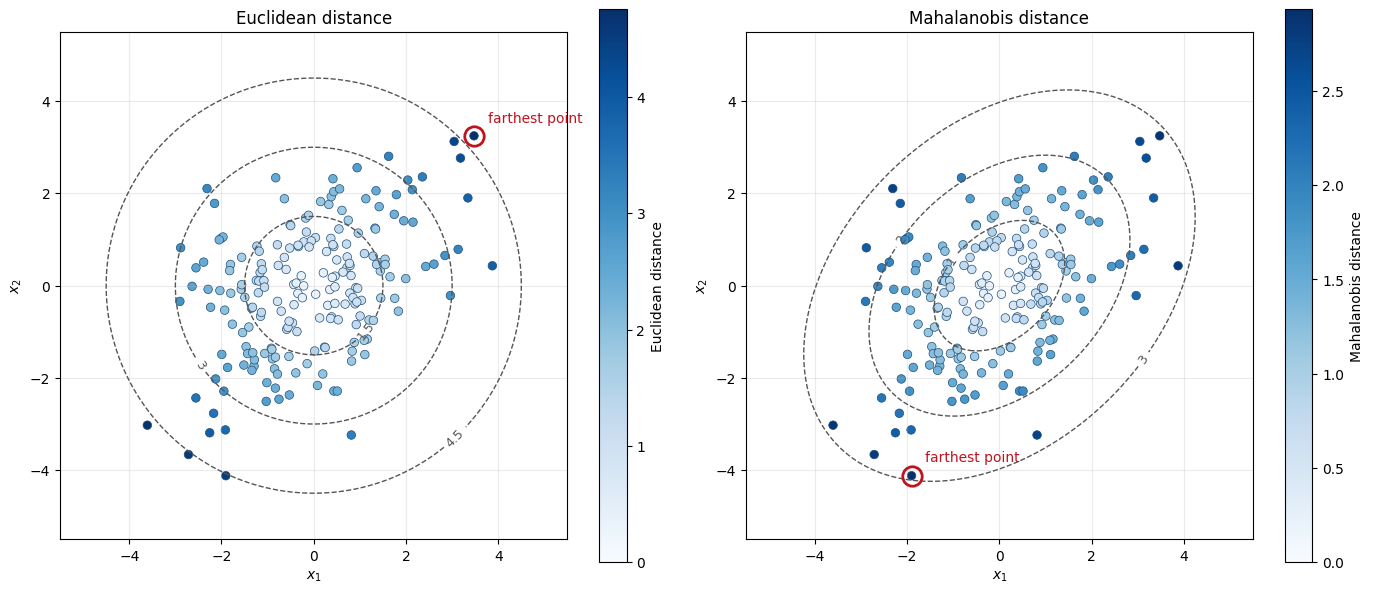

In [6]:
plot_distances(points, Sigma)

## The effect of the correlation

With no correlation and equal variances both distances agree (up to the scale). The more correlated the variables, the more they differ. Move the slider to change the correlation (this cell needs a running kernel).

In [ ]:
def interactive_distances(rho):
    Sigma_rho = 2*np.array([[1, rho], [rho, 1]])
    points_rho = np.random.default_rng(111).multivariate_normal(mu, Sigma_rho, 200)
    plot_distances(points_rho, Sigma_rho)

interact(interactive_distances, rho=FloatSlider(value=0.35, min=-0.95, max=0.95, step=0.05, description='correlation'));

interactive(children=(FloatSlider(value=0.35, description='correlation', max=0.95, min=-0.95, step=0.05), Outp…

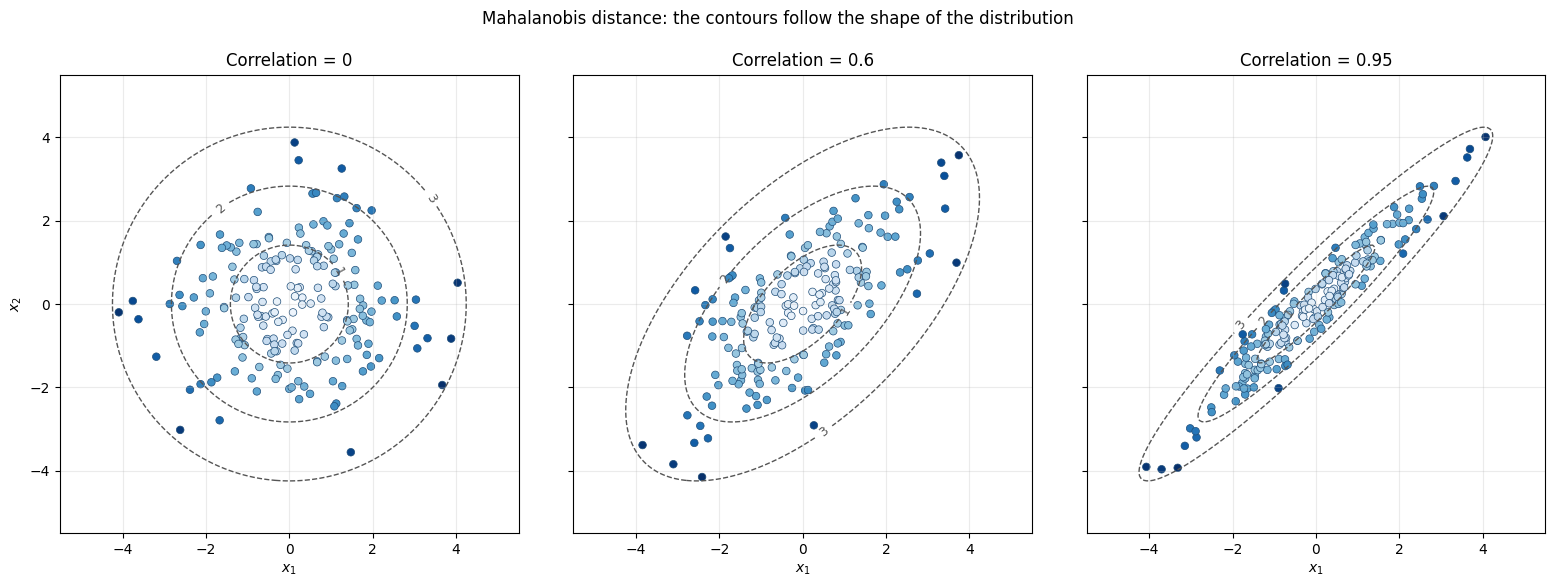

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.6), sharey=True)
for ax, rho in zip(axes, [0, 0.6, 0.95]):
    Sigma_rho = 2*np.array([[1, rho], [rho, 1]])
    points_rho = np.random.default_rng(111).multivariate_normal(mu, Sigma_rho, 200)
    D_rho = np.sqrt(np.sum(((points_rho-mu) @ np.linalg.inv(Sigma_rho)) * (points_rho-mu), axis=1))
    G_1, G_2, grid_E, grid_M = distance_grid(Sigma_rho)

    CS = ax.contour(G_1, G_2, grid_M, levels=[1, 2, 3], colors='#555555', linewidths=1, linestyles='--')
    ax.clabel(CS, fmt='%g', fontsize=9)
    ax.scatter(points_rho[:, 0], points_rho[:, 1], c=D_rho, cmap='Blues', vmin=0, s=30,
               edgecolor='#1f4e79', linewidth=0.5)
    ax.set_aspect('equal')
    ax.set_xlim(-5.5, 5.5)
    ax.set_ylim(-5.5, 5.5)
    ax.set_xlabel('$x_1$')
    ax.set_title(f'Correlation = {rho}')
    ax.grid(True, alpha=0.25)
axes[0].set_ylabel('$x_2$')
fig.suptitle('Mahalanobis distance: the contours follow the shape of the distribution')
fig.tight_layout(rect=(0, 0, 1, 0.95))